# Experimental images to colony-area evaluation

Figure 5G uses the area output of the existing trained two-output model. No retraining or checkpoint architecture changes.

Extra diagnostics are preserved in `Misc/notebook_sections/information_encoding_decoding/colonyarea_extra_diagnostics.ipynb`.


In [1]:
import json
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from natsort import natsorted
from torch.utils.data import DataLoader

from colonyarea_dataset import MyDataset
from models.ResNet import ColonyMetricsResNet
from utils.config import (
    CKPT_PATH_EXPTOCOLONYMETRICS,
    EXP_FOLDER_TEST,
    EXP_FOLDER_TEST_COLONYMETRICS,
)
from utils.preprocess import preprocess_experimental_backgroundblack_blackandwhite

/hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-11-03 06:48:57,641] [INFO] [real_accelerator.py:110:get_accelerator] Setting ds_accelerator to cuda (auto detect)


/hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


## Generate experimental test-set ground truth

Use the existing cropped-image preprocessing for the area target. Tip labels remain available for compatibility with the two-output checkpoint.


In [2]:
def sample_boundary_ring(mask, radius_frac=0.95, n_samples=1440):
    height, width = mask.shape
    center_y, center_x = height / 2, width / 2
    radius = min(height, width) / 2 * radius_frac
    angles = np.linspace(0, 2 * np.pi, n_samples, endpoint=False)
    xs = np.clip((center_x + radius * np.cos(angles)).astype(int), 0, width - 1)
    ys = np.clip((center_y + radius * np.sin(angles)).astype(int), 0, height - 1)
    return mask[ys, xs] == 255


def count_circular_runs(binary_profile):
    if binary_profile.all():
        return 1
    if not binary_profile.any():
        return 0
    start = np.argmax(~binary_profile)
    rolled = np.roll(binary_profile, -start)
    return int(np.sum(np.diff(rolled.astype(int)) == 1))


def calculate_colony_metrics(mask):
    colony_area_px = int(np.count_nonzero(mask == 255))
    return {
        "colony_area_px": colony_area_px,
        "colony_area_fraction": float(colony_area_px / mask.size),
        "number_of_tips": count_circular_runs(sample_boundary_ring(mask)),
    }

In [3]:
test_files = natsorted(
    filename for filename in os.listdir(EXP_FOLDER_TEST)
    if os.path.splitext(filename)[1].lower() in {".tif", ".tiff", ".png"}
)

test_records = []
for filename in test_files:
    image_path = os.path.join(EXP_FOLDER_TEST, filename)
    mask = preprocess_experimental_backgroundblack_blackandwhite(image_path)
    height, width = mask.shape
    test_records.append({
        "image": {
            "filename": filename,
            "path": image_path,
            "width_px": int(width),
            "height_px": int(height),
        },
        "metrics": calculate_colony_metrics(mask),
    })

with open(EXP_FOLDER_TEST_COLONYMETRICS, "w", encoding="utf-8") as file_handle:
    json.dump({"images": test_records}, file_handle, indent=2)

print(f"Saved {len(test_records)} test records to {EXP_FOLDER_TEST_COLONYMETRICS}")

Saved 96 test records to /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/exp_test_colony_metrics.json


## Check the two evaluation preprocessing paths

The color image is cropped and converted to the white-background representation for model inference. The binary mask is produced separately and is used only to calculate ground-truth metrics.

In [ ]:
from utils.preprocess import preprocess_experimental_backgroundwhite

n_check = min(4, len(test_files))
fig, axes = plt.subplots(n_check, 3, figsize=(11, 3 * n_check))
if n_check == 1:
    axes = np.expand_dims(axes, axis=0)

for row, filename in enumerate(test_files[:n_check]):
    image_path = os.path.join(EXP_FOLDER_TEST, filename)
    raw_image = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    model_input = preprocess_experimental_backgroundwhite(image_path)
    model_input = cv2.resize(model_input, (256, 256))
    ground_truth_mask = preprocess_experimental_backgroundblack_blackandwhite(image_path)
    metrics = calculate_colony_metrics(ground_truth_mask)

    axes[row, 0].imshow(raw_image)
    axes[row, 0].set_title(f"Raw: {filename}")
    axes[row, 1].imshow(model_input)
    axes[row, 1].set_title("Cropped model input\nwhite-background preprocessing")
    axes[row, 2].imshow(ground_truth_mask, cmap="gray")
    axes[row, 2].set_title(
        f"Ground-truth mask\narea={metrics['colony_area_fraction']:.3f}, "
    )
    for axis in axes[row]:
        axis.axis("off")

plt.tight_layout()
plt.show()

## Load the configured labels and trained model

In [5]:
test_dataset = MyDataset(
    source_folder=EXP_FOLDER_TEST,
    metrics_json_path=EXP_FOLDER_TEST_COLONYMETRICS,
    preprocess_input="backgroundwhite",
)
test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False, num_workers=0, pin_memory=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ColonyMetricsResNet.load_from_checkpoint(
    CKPT_PATH_EXPTOCOLONYMETRICS, map_location=device
)
model.to(device)
model.eval()
print(f"Loaded {len(test_dataset)} test images on {device}")

Loaded 96 test images on cuda


In [6]:
prediction_records = []
with torch.no_grad():
    for batch in test_loader:
        source = batch["source"].to(device)
        area_prediction, transformed_tip_prediction = model(source)
        tip_prediction = model.inverse_tip_prediction(transformed_tip_prediction)

        for index, stem in enumerate(batch["stem"]):
            prediction_records.append({
                "stem": stem,
                "area_target": batch["colony_area_fraction"][index].item(),
                "area_prediction": area_prediction[index].item(),
                "tips_target": batch["number_of_tips"][index].item(),
                "tips_prediction": tip_prediction[index].item(),
            })

results = pd.DataFrame(prediction_records)
results.head()

,stem,area_target,area_prediction,tips_target,tips_prediction
0,196_1,0.271790,0.297622,4.0,13.945780
1,196_2,0.306885,0.343755,12.0,26.173107
2,197_1,0.528290,0.518511,32.0,40.510704
3,197_2,0.524521,0.520611,30.0,35.590168
4,198_1,0.155579,0.187764,0.0,0.020790


## Regression metrics

In [ ]:
def regression_metrics(target, prediction):
    target = np.asarray(target, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    residual = prediction - target
    mse = np.mean(residual ** 2)
    target_ss = np.sum((target - target.mean()) ** 2)
    r_squared = 1 - np.sum(residual ** 2) / target_ss if target_ss > 0 else np.nan
    pearson = np.corrcoef(target, prediction)[0, 1]
    return {
        "MAE": np.mean(np.abs(residual)),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r_squared,
        "Pearson_r": pearson,
    }


metric_summary = pd.DataFrame({
    "colony_area_fraction": regression_metrics(
        results["area_target"], results["area_prediction"]
    ),
}).T
display(metric_summary)


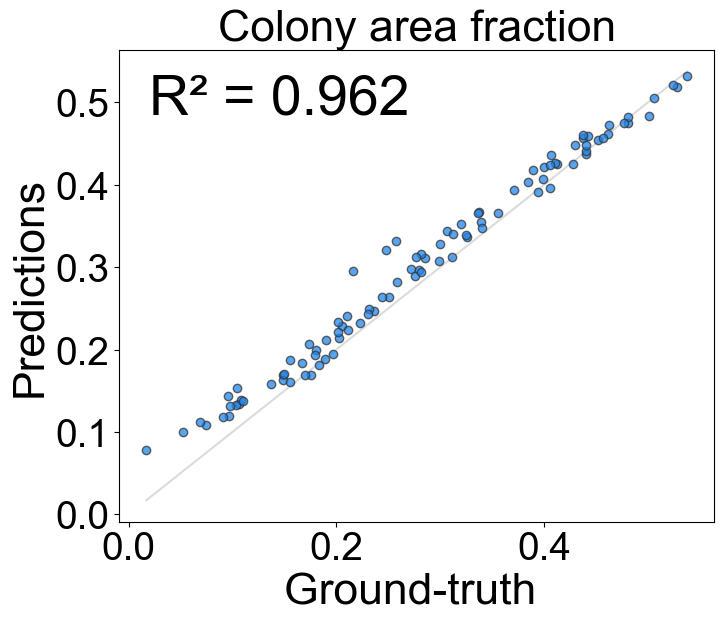

In [29]:
from matplotlib import font_manager
from utils.config import FPATH

# Register the configured Arial font and keep these settings local to this plot.
font_manager.fontManager.addfont(str(FPATH))
plot_font_family = font_manager.FontProperties(fname=str(FPATH)).get_name()
plot_style = {
    "font.family": plot_font_family,
    "font.size": 32,
    "axes.labelsize": 32,
    "axes.titlesize": 36,
    "xtick.labelsize": 28,
    "ytick.labelsize": 28,
    "legend.fontsize": 28,
}

target = results["area_target"]
prediction = results["area_prediction"]
r_squared = regression_metrics(target, prediction)["R2"]
lower = min(target.min(), prediction.min())
upper = max(target.max(), prediction.max())

with plt.rc_context(plot_style):
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.plot([lower, upper], [lower, upper], "-", color="#D3D3D3", alpha=0.8, zorder=1)
    ax.scatter(
        target, prediction, alpha=0.75, color="#2185EA",
        edgecolor="#333333", linewidth=1.0, zorder=2,
    )
    ax.set_xlabel("Ground-truth ")
    ax.set_ylabel("Predictions")
    ax.set_title('Colony area fraction',fontdict={"fontsize": 32})
  
    # ax.set_title("Colony area fraction")
    ax.text(
        0.05, 0.95, f"R² = {r_squared:.3f}",
        transform=ax.transAxes, ha="left", va="top", fontsize=40,
    )
    # ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()


In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Fig. 5G — colony-area regression
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'information_encoding_decoding' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'Fig5G_colony_area_regression.pdf')
